### Here we will create a QNN with one cubit. The goal is to create synthetic data (maybe around 100-1000 points) on the unit square. We then assign each datapoint a value (1 if inside circle with radius .5 centered at .5,.5 or 0 if not)

In [9]:
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler
import qiskit.quantum_info as qi
import numpy as np

# Sample the bivariate uniform dist
n = 1000
X = np.random.uniform(size=(2,n))
# r, h, k
circle = (.5, .5, .5)

# Okay, now we need our labels and we will zip them up.
def in_out(x,y,circle):
    r = circle[0]
    h = circle[1]
    k = circle[2]

    return r**2 >= (x-h)**2+(y-k)**2


labels = in_out(x=X[0,:], y=X[1,:], circle=circle)
print(np.shape(labels))
np.reshape(labels, (1,n))
print(np.shape(labels))

XY = np.vstack((X,labels))
print(f' dataframe shape: {np.shape(XY)}')


(1000,)
(1000,)
 dataframe shape: (3, 1000)


#### We now have our dataset

#### We proceed to think about how to encode the tuples into a single qubit.

In [10]:
# Perhaps we could try to use the qubit superposition values.
from qiskit.circuit import Parameter

# Let's make a circuit
qc = QuantumCircuit(1) # one qubit
x = Parameter('x')
y = Parameter('y')



# Encoding the x,y pair as bloch sphere angles


#### $\ket0R_y(x\pi)$ and $R_z(y\pi)$ Will be our rotations

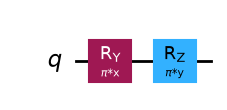

In [11]:
qc.ry((x*np.pi),0)
qc.rz((y*np.pi),0)

qc.draw('mpl')


#### We now encode the first training point

In [14]:
x_val = X[0, 0]
y_val = X[1, 0]

encoded_qc = qc.assign_parameters({
x: x_val,
y: y_val
})

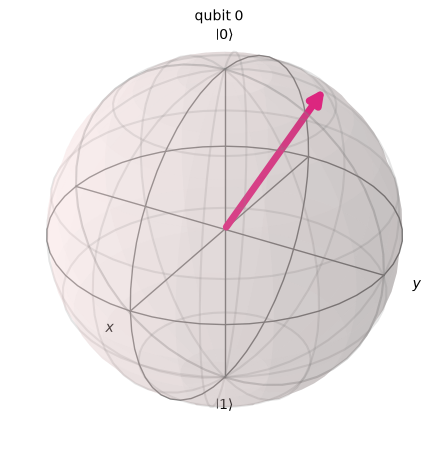

In [15]:
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_bloch_multivector

state = Statevector.from_instruction(encoded_qc)

plot_bloch_multivector(state)

In [ ]:
# Okay. We have solved the encoding issue. 
# Now we want to train. We'll use the normal training method 
# But we'll change what x and y are multiplied by

'''
                Qiskit
(x,y, θ) ───────────────→ prediction
                              │
                              ▼
                           loss
                              │
                              ▼
                    classical optimizer
                              │
                              ▼
                         new θ values
'''

In [ ]:
# So we won't be training the embeddings. 
# Let the rotations based on x,y be consistent. 
# We will train additional rotations, after the two, 
# based on theta 1 and theta 2

# Then we get some state and if we ask what the
#  probability of measuring a Z is.

# 1) create symbolic input params
x = Parameter('x')
y = Parameter('y')

# 2) Trainable params theta1, theta2, theta3
t1 = Parameter('t1')
t2 = Parameter('t2')
t3 = Parameter('t3')

# 3) Make 1 qubit circuit
q = QuantumCircuit(1)

# 4) Encode the data
q.ry(np.pi*x)
